# Topic 21d - Distributions

The main lesson showed one histogram and one box plot. This notebook covers reading a box plot's five numbers precisely, comparing more than two groups at once, and a log-scale histogram for the cases a linear one cannot show.

Work through it after reading section 5 of the [main lesson](topic21_data_visualization.ipynb).

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "data_visualization" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "orders.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find orders.csv. Expected a data folder containing the six "
        "Topic 20/21 tables. Looked in: " + ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

# The course palette. Hues are assigned in this fixed order to every chart in
# Topic 21 - never cycled, never re-generated - so a category keeps the same
# colour in every chart it appears in. See 21a for why this matters.
PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"    # de-emphasis grey, for "everything but the finding"
INK = "#0b0b0b"      # text and value labels

# Fixed colour assignment per category, used throughout this topic.
ZONE_COLOR = {"Coastal": PALETTE["blue"], "Middle": PALETTE["aqua"], "Northern": PALETTE["yellow"]}
CHANNEL_COLOR = {"Field Agent": PALETTE["blue"], "Online": PALETTE["aqua"],
                 "Phone": PALETTE["yellow"], "Shop": PALETTE["green"]}
SEGMENT_COLOR = {"Retail": PALETTE["blue"], "Wholesale": PALETTE["aqua"], "Institution": PALETTE["yellow"]}
CATEGORY_COLOR = {
    "Beverages": PALETTE["blue"], "Grains": PALETTE["aqua"], "Cooking Oils": PALETTE["yellow"],
    "Personal Care": PALETTE["green"], "Household": PALETTE["violet"], "Snacks": PALETTE["red"],
    "Canned Goods": PALETTE["magenta"],
}

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/data_visualization/data
files:             ['customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
# Paste the function you built in Topic 20. This is the same contract: five
# raw tables in, one analysis-ready table out, with its own row-count check.
def clean_region(series):
    return (series.str.strip()
                  .str.replace(r"\s+", " ", regex=True)
                  .str.title())


def build_analysis_table(orders, customers, products, regions, returns):
    """Combine the five raw tables into one analysis-ready table (Topic 20)."""
    expected_rows = len(orders)

    customers = customers.copy()
    customers["region"] = clean_region(customers["region"])
    products = products.drop_duplicates(subset="product_id", keep="first")
    customers = customers.merge(regions, on="region", how="left", validate="m:1")

    table = (orders
             .merge(customers, on="customer_id", how="left", validate="m:1")
             .merge(products, on="product_id", how="left", validate="m:1"))

    returned_ids = set(returns["order_id"])
    table["was_returned"] = table["order_id"].isin(returned_ids)

    table["order_date"] = pd.to_datetime(table["order_date"])
    table["month"] = table["order_date"].dt.strftime("%b")
    table["weekday"] = table["order_date"].dt.day_name()
    table["revenue_ghs"] = (table["quantity"] * table["unit_price_ghs"]).round(2)
    table["cost_ghs"] = (table["quantity"] * table["unit_cost_ghs"]).round(2)
    table["profit_ghs"] = (table["revenue_ghs"] - table["cost_ghs"]).round(2)

    if len(table) != expected_rows:
        raise ValueError(
            f"Row count changed during wrangling: {expected_rows} -> {len(table)}. "
            "A merge has duplicated rows."
        )
    return table.sort_values("order_date").reset_index(drop=True)


orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
regions = pd.read_csv(DATA_DIR / "regions.csv")
returns = pd.read_csv(DATA_DIR / "returns.csv")
targets_wide = pd.read_csv(DATA_DIR / "monthly_targets_wide.csv")

analysis = build_analysis_table(orders, customers, products, regions, returns)
print(f"Analysis table: {analysis.shape[0]} rows x {analysis.shape[1]} columns")
print(f"Total revenue: GHS {analysis['revenue_ghs'].sum():,.2f}")
print(f"Total profit:  GHS {analysis['profit_ghs'].sum():,.2f}")

Analysis table: 1200 rows x 24 columns
Total revenue: GHS 230,001.08
Total profit:  GHS 65,886.38


---

## Reading a box plot

A box plot draws five numbers: the box spans the 25th to 75th percentile (the middle 50% of the data, the **interquartile range** or IQR), the line inside it is the median, the whiskers extend to the most extreme point within 1.5x the IQR, and anything beyond that is drawn as an individual dot - an **outlier** by this specific, computable definition, not a vague "unusually large value."

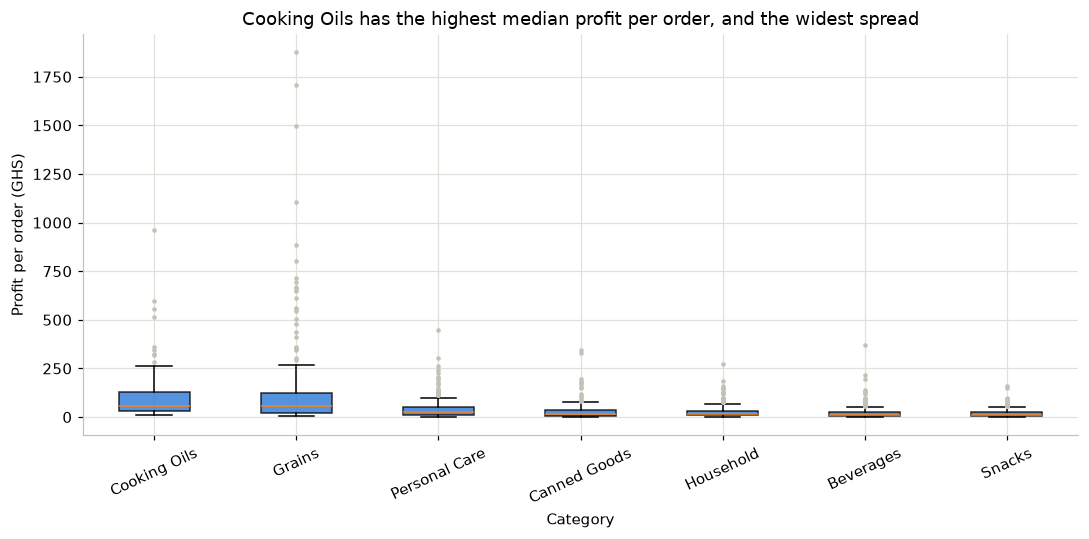

category
Cooking Oils     56.13
Grains           55.50
Personal Care    24.21
Canned Goods     16.03
Household        15.12
Beverages        10.88
Snacks           10.40


In [3]:
category_order = (analysis.groupby("category")["profit_ghs"].median()
                   .sort_values(ascending=False).index.tolist())
box_data = [analysis.loc[analysis["category"] == cat, "profit_ghs"].dropna() for cat in category_order]

fig, ax = plt.subplots(figsize=(10, 5))
bp = ax.boxplot(box_data, tick_labels=category_order, patch_artist=True,
                 flierprops={"markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": "none"})
for patch in bp["boxes"]:
    patch.set_facecolor(PALETTE["blue"])
    patch.set_alpha(0.8)

ax.set_title("Cooking Oils has the highest median profit per order, and the widest spread")
ax.set_xlabel("Category")
ax.set_ylabel("Profit per order (GHS)")
ax.tick_params(axis="x", rotation=25)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

medians = analysis.groupby("category")["profit_ghs"].median().sort_values(ascending=False)
print(medians.round(2).to_string())

Sorting the categories by median (`category_order`, built before the plotting call) rather than alphabetically is deliberate - a reader scanning left to right sees the ranking immediately, the same reason the bar charts in 21b sort instead of defaulting to CSV order.

---

## A log-scale histogram, for the cases a linear one cannot show

The main lesson's revenue histogram worked because most orders cluster under GHS 400, with a long but visible tail. Unit price has the same right-skew problem in a more extreme form - a linear-scale histogram crams almost every order into the first few bins and leaves the rest of the axis empty.

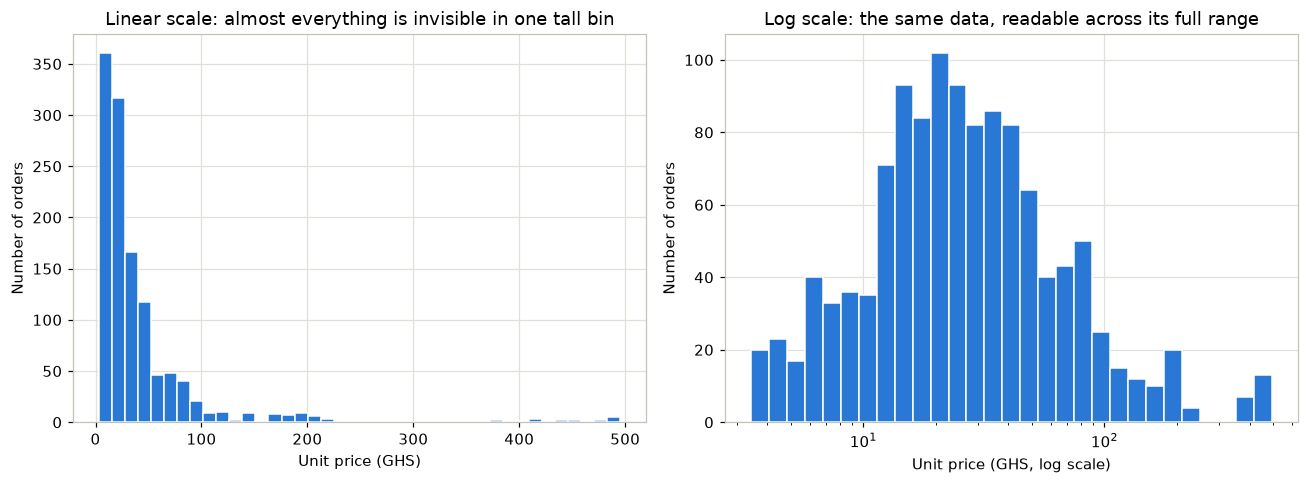

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(analysis["unit_price_ghs"], bins=40, color=PALETTE["blue"], edgecolor="white")
axes[0].set_title("Linear scale: almost everything is invisible in one tall bin")
axes[0].set_xlabel("Unit price (GHS)")
axes[0].set_ylabel("Number of orders")

axes[1].hist(analysis["unit_price_ghs"], bins=np.logspace(
    np.log10(analysis["unit_price_ghs"].min()), np.log10(analysis["unit_price_ghs"].max()), 30),
    color=PALETTE["blue"], edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_title("Log scale: the same data, readable across its full range")
axes[1].set_xlabel("Unit price (GHS, log scale)")
axes[1].set_ylabel("Number of orders")

fig.tight_layout()
plt.show()

A log scale is the right call when a measure spans **orders of magnitude** (here, GHS 3.42 to GHS 495.28) and you care about relative differences across that whole range - never apply it by default, and always say so in the axis label (`"... (log scale)"`), because a reader who misses that note will misjudge every distance on the chart.

### Try It 4 - describe a distribution in words

Pick any one category and compute, for its `profit_ghs`: the median, the IQR, and the number of outliers by the 1.5x-IQR rule. Then write one sentence - with all three numbers in it - that you could put in a report without needing the chart next to it.

In [5]:
# YOUR CODE HERE

---
## Where this fits

- [Back to the main lesson](topic21_data_visualization.ipynb)
- Previous: [21c - Change over time](topic21c_change_over_time.ipynb)
- Next: [21e - Relationships](topic21e_relationships.ipynb)